# No-U-Turn Sampler (NUTS)

NUTS removes the need to hand-tune the trajectory length in Hamiltonian Monte Carlo. At each step it doubles a balanced binary tree of leapfrog states forward or backward in time, stopping as soon as the trajectory "U-turns" on itself, then samples one state from the explored set, weighted by $\exp(-H)$.

We use the multinomial-sampling variant (Betancourt 2016) and adapt the step size via dual averaging (Nesterov 2009; Hoffman & Gelman 2014) during a warmup phase.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))

import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import matplotlib.pyplot as plt

from mcmc_samplers import HamiltonianMonteCarlo, NUTS, SampleVisualizer, diagnostics

In [2]:
class Banana:
    def __init__(self):
        self.mvn = MultivariateNormal(torch.zeros(2), torch.tensor([[1.0, 0.9], [0.9, 1.0]]))
    def __call__(self, x):
        y = torch.stack([x[..., 0], x[..., 1] + (x[..., 0] + 1.0) ** 2], dim=-1)
        return self.mvn.log_prob(y)

target = Banana()
x0 = torch.tensor([0.0, -1.0])

## Run NUTS with dual-averaging warmup

The first `warmup` iterations adapt the step size to hit the target acceptance probability of 0.8. After warmup the step size is locked at the running smoothed average.

In [3]:
warmup = 500
N = 3500

nuts = NUTS(target=target, x0=x0, step_size=0.5, warmup=warmup, target_accept=0.8, max_depth=8, generator=torch.Generator().manual_seed(0))
step_size_trace = []
tree_depth_trace = []

def callback(step, sample, accepted):
    step_size_trace.append(nuts.dynamics.step_size)
    tree_depth_trace.append(nuts.last_tree_depth)

samples, _ = nuts(N, burn_in=warmup, callback=callback)

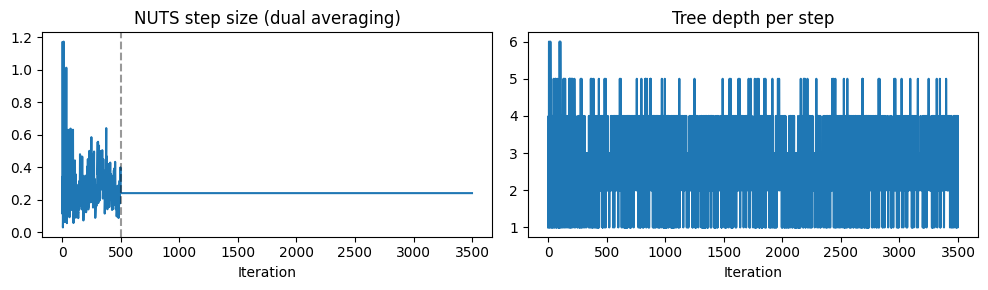

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(step_size_trace)
axs[0].axvline(warmup, linestyle='--', color='k', alpha=0.4)
axs[0].set_title('NUTS step size (dual averaging)')
axs[0].set_xlabel('Iteration')
axs[1].plot(tree_depth_trace)
axs[1].set_title('Tree depth per step')
axs[1].set_xlabel('Iteration')
plt.tight_layout()
plt.show()

## Compare against vanilla HMC

Both samplers see the same number of post-warmup samples. On this small target, HMC with a hand-picked step size and trajectory length actually reaches a higher ESS than NUTS. The point of NUTS is that it needs neither choice: it adapts the step size during warmup and picks the trajectory length at every step. Fixed-length HMC is only as good as its settings, which usually take trial and error and can fail badly (for example, getting stuck in the banana's narrow tail).

In [5]:
hmc = HamiltonianMonteCarlo(target=target, x0=x0, step_size=0.2, num_steps=5, generator=torch.Generator().manual_seed(7))
hmc_samples, _ = hmc(N, burn_in=warmup)

print(f'NUTS acceptance (avg tree): {nuts.last_alpha:.3f}; final step size {nuts.dynamics.step_size:.3f}')
print(f'HMC  acceptance: {100*hmc.acceptance_ratio:.1f}%')

print('NUTS ESS:', diagnostics.effective_sample_size(samples).tolist())
print('HMC  ESS:', diagnostics.effective_sample_size(hmc_samples).tolist())

NUTS acceptance (avg tree): 0.996; final step size 0.241
HMC  acceptance: 87.7%
NUTS ESS: [84.41439819335938, 118.60478973388672]
HMC  ESS: [193.1676025390625, 178.0939483642578]


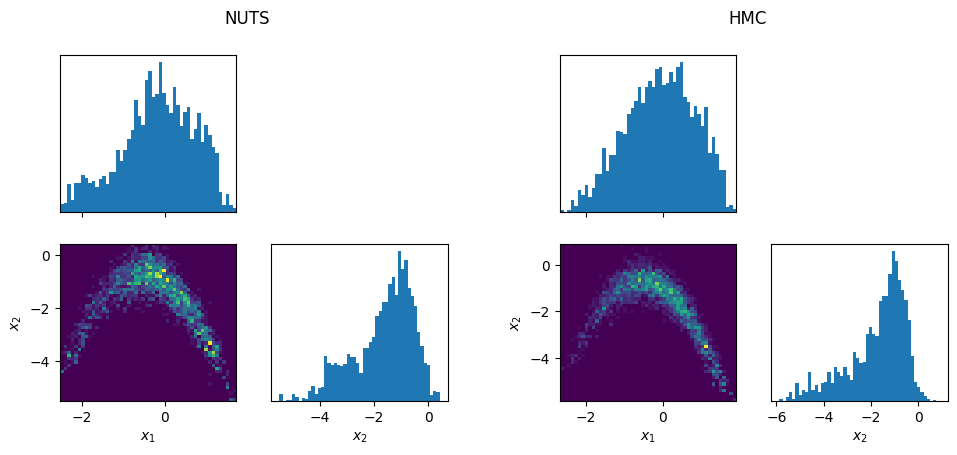

In [6]:
# Joint and marginal histograms, side by side
fig = plt.figure(figsize=(10, 4.5))
for subfig, (s, title) in zip(fig.subfigures(1, 2), [(samples, 'NUTS'), (hmc_samples, 'HMC')]):
    SampleVisualizer(s).triangular_hist(bins=50, labels=['$x_1$', '$x_2$'], titles=[title], fig=subfig)
plt.show()